# CS224N Assignment 1: 探索词向量

In [1]:
# All Import Statements Defined Here
# Note: Do not add to this list.
# ----------------

import sys
# Check if python version is at least 3.8
assert sys.version_info[0] == 3
assert sys.version_info[1] >= 8

from platform import python_version
assert int(python_version().split(".")[1]) >= 5, "Please upgrade your Python version following the instructions in \
    the README.md file found in the same directory as this notebook. Your Python version is " + python_version()

from gensim.models import KeyedVectors
from gensim.test.utils import datapath
import pprint
import matplotlib.pyplot as plt
plt.rcParams['figure.figsize'] = [10, 5]

from datasets import load_dataset
imdb_dataset = load_dataset("stanfordnlp/imdb")

import re
import numpy as np
import random
import scipy as sp
from sklearn.decomposition import TruncatedSVD
from sklearn.decomposition import PCA

START_TOKEN = '<START>'
END_TOKEN = '<END>'
NUM_SAMPLES = 150

np.random.seed(0)
random.seed(0)
# ----------------

Generating train split:   0%|          | 0/25000 [00:00<?, ? examples/s]

Generating test split:   0%|          | 0/25000 [00:00<?, ? examples/s]

Generating unsupervised split:   0%|          | 0/50000 [00:00<?, ? examples/s]

## Word Vectors
词向量通常是下游自然语言处理（NLP）任务的基础组成部分，例如问答、文本生成、翻译等。因此，建立对其优势与局限的直观认识非常重要。在本次作业中，你将探索两类词向量：一类由*共现矩阵（co-occurrence matrices）*生成，另一类通过 GloVe 方法生成。

术语说明：“词向量（word vectors）”和“词嵌入（word embeddings）”这两个术语经常互换使用。“嵌入”指的是：我们在一个较低维度的空间中，编码一个词的部分语义信息。正如维基百科所述：“从概念上讲，这涉及一种数学嵌入，将每个词各占一个维度的空间，映射到维度低得多的连续向量空间。”

## 第一部分：基于计数的词向量（10 分）

大多数词向量模型都以如下思想为出发点：

*“观其伴，知其义。”——一个词的含义，可以通过经常与它一起出现的词来了解。([Firth, J. R. 1957:11](https://en.wikipedia.org/wiki/John_Rupert_Firth))*

许多词向量的实现都基于这样一个观点：含义相似的词，即同义词或近义词，会出现在相似的上下文中。因此，当这些词出现在口语或书面语中时，它们周围经常会出现一部分相同的词，这些周围的词就构成了它们的**上下文（context）**。通过考察这些上下文，我们可以尝试为词构建嵌入表示。

基于这一直觉，许多“传统”的词向量构建方法都依赖于词频统计。接下来，我们将详细介绍其中一种方法：**共现矩阵（co-occurrence matrices）**。更多信息可参阅[这份教材](https://web.stanford.edu/~jurafsky/slp3/6.pdf)或[这篇文章](https://web.archive.org/web/20190530091127/https://medium.com/data-science-group-iitr/word-embedding-2d05d270b285)。

### 共现（Co-Occurrence）

共现矩阵用于统计事物在某种环境中共同出现的频次。对于文档中出现的某个词 $w_i$，我们考察它周围的*上下文窗口（context window）*。假设固定窗口大小为 $n$，则该窗口包含文档中位于 $w_i$ 前面的 $n$ 个词和后面的 $n$ 个词，即 $w_{i-n} \dots w_{i-1}$ 和 $w_{i+1} \dots w_{i+n}$。

我们构建一个*共现矩阵* $M$。它是一个以词为行、以词为列的对称矩阵，其中 $M_{ij}$ 表示：在所有文档中，词 $w_j$ 出现在词 $w_i$ 的上下文窗口内的总次数。

**示例：固定窗口大小为 $n=1$ 时的共现统计**

文档 1："all that glitters is not gold"（闪光的未必都是金子）

文档 2："all is well that ends well"（结局好，一切都好）

| * | `<START>` | all | that | glitters | is | not | gold | well | ends | `<END>` |
|---|---|---|---|---|---|---|---|---|---|---|
| `<START>` | 0 | 2 | 0 | 0 | 0 | 0 | 0 | 0 | 0 | 0 |
| all | 2 | 0 | 1 | 0 | 1 | 0 | 0 | 0 | 0 | 0 |
| that | 0 | 1 | 0 | 1 | 0 | 0 | 0 | 1 | 1 | 0 |
| glitters | 0 | 0 | 1 | 0 | 1 | 0 | 0 | 0 | 0 | 0 |
| is | 0 | 1 | 0 | 1 | 0 | 1 | 0 | 1 | 0 | 0 |
| not | 0 | 0 | 0 | 0 | 1 | 0 | 1 | 0 | 0 | 0 |
| gold | 0 | 0 | 0 | 0 | 0 | 1 | 0 | 0 | 0 | 1 |
| well | 0 | 0 | 1 | 0 | 1 | 0 | 0 | 0 | 1 | 1 |
| ends | 0 | 0 | 1 | 0 | 0 | 0 | 0 | 1 | 0 | 0 |
| `<END>` | 0 | 0 | 0 | 0 | 0 | 0 | 1 | 1 | 0 | 0 |

在自然语言处理（NLP）中，我们通常使用 `<START>` 和 `<END>` 标记（token）来表示句子、段落或文档的开始与结束。这些标记也参与共现次数的统计，并分别放在每篇文档的开头和结尾。例如：

`<START> All that glitters is not gold <END>`

矩阵的每一行（或每一列）都可以作为一个基于词与词共现关系的词向量，但这些向量的维度可能很高。为了降低维度，我们使用**奇异值分解（Singular Value Decomposition，SVD）**，其思路类似于主成分分析（PCA），选取前 $k$ 个主要成分。SVD 将共现矩阵 $A$ 分解，其中对角矩阵 $S$ 存储奇异值，而 $U_k$ 则提供新的、维度更低的词向量。

这种降维方法能够保留语义关系。例如，*doctor*（医生）与 *hospital*（医院）的向量距离，会比 *doctor*（医生）与 *dog*（狗）的向量距离更近。

如果你还不熟悉特征值和 SVD，可以阅读[这份适合初学者的 SVD 教程](https://davetang.org/file/Singular_Value_Decomposition_Tutorial.pdf)。如果希望深入理解，还可以参考 CS168 的第 [7](https://web.stanford.edu/class/cs168/l/l7.pdf)、[8](http://theory.stanford.edu/~tim/s15/l/l8.pdf)、[9](https://web.stanford.edu/class/cs168/l/l9.pdf) 讲，这些讲义从整体层面介绍了相关算法。

实际实现时，建议使用 NumPy、SciPy 或 scikit-learn 等 Python 库中已经实现好的函数。对大型语料库执行完整的 SVD 可能会消耗大量内存，不过也有适用于大规模数据的方法，例如**截断奇异值分解（Truncated SVD）**，可以高效地提取前 $k$ 个向量成分。

### 绘制基于共现的词嵌入

这里，我们将使用**大型电影评论数据集（Large Movie Review Dataset）**。这是一个用于二分类情感分析的数据集，其数据量远大于以往的基准数据集。该数据集提供了 25,000 条情感倾向鲜明的电影评论用于训练，另有 25,000 条用于测试。此外，还有额外的未标注数据可供使用。

下面提供的 `read_corpus` 函数会从数据集中提取电影评论文本。该函数还会在每篇文档的开头和结尾分别添加 `<START>` 和 `<END>` 标记，并将所有单词转换为小写。你**不需要**进行任何其他预处理。

In [2]:
def read_corpus():
    """ 读取大型电影评论数据集中的文件。
        Params:
            category (string)：类别名称。
        Return:
            一个由列表组成的列表，每个子列表包含一个经过处理的文件中的单词。
    """
    files = imdb_dataset["train"]["text"][:NUM_SAMPLES]
    return [[START_TOKEN] + [re.sub(r'[^\w]', '', w.lower()) for w in f.split(" ")] + [END_TOKEN] for f in files]

In [8]:
imdb_corpus = read_corpus()
# 查看前 3 条影评
pprint.pprint(imdb_corpus[:3], compact=True, width=100)
print("corpus size: ", len(imdb_corpus[0])) # 第一条影评约有 290 个词

[['<START>', 'i', 'rented', 'i', 'am', 'curiousyellow', 'from', 'my', 'video', 'store', 'because',
  'of', 'all', 'the', 'controversy', 'that', 'surrounded', 'it', 'when', 'it', 'was', 'first',
  'released', 'in', '1967', 'i', 'also', 'heard', 'that', 'at', 'first', 'it', 'was', 'seized',
  'by', 'us', 'customs', 'if', 'it', 'ever', 'tried', 'to', 'enter', 'this', 'country', 'therefore',
  'being', 'a', 'fan', 'of', 'films', 'considered', 'controversial', 'i', 'really', 'had', 'to',
  'see', 'this', 'for', 'myselfbr', 'br', 'the', 'plot', 'is', 'centered', 'around', 'a', 'young',
  'swedish', 'drama', 'student', 'named', 'lena', 'who', 'wants', 'to', 'learn', 'everything',
  'she', 'can', 'about', 'life', 'in', 'particular', 'she', 'wants', 'to', 'focus', 'her',
  'attentions', 'to', 'making', 'some', 'sort', 'of', 'documentary', 'on', 'what', 'the', 'average',
  'swede', 'thought', 'about', 'certain', 'political', 'issues', 'such', 'as', 'the', 'vietnam',
  'war', 'and', 'race', 'issu

### 问题 1.1：实现 `distinct_words`［编程题］（2 分）

编写一个函数，找出语料库中出现的所有不重复的词（即词类型，word types）。

你可以使用 `for` 循环处理输入的 `corpus`（一个由字符串列表组成的列表），但建议尝试使用 Python 列表推导式，因为它通常更快。尤其是，[这篇文章](https://coderwall.com/p/rcmaea/flatten-a-list-of-lists-in-one-line-in-python)介绍了如何将嵌套列表展平为一个列表，可能会对你有所帮助。如果你还不熟悉 Python 列表推导式，可以参考[这份资料](https://python-3-patterns-idioms-test.readthedocs.io/en/latest/Comprehensions.html)。

返回的 `corpus_words` 应当按顺序排列。你可以使用 Python 的 `sorted` 函数进行排序。

你可能会发现，使用 [Python 集合（set）](https://www.w3schools.com/python/python_sets.asp)去除重复的词会很方便。

In [15]:
def distinct_words(corpus):
    """ 确定语料库中不重复的词的列表。
        Params：
            corpus (list of list of strings)：文档语料库
        Return：
            corpus_words (list of strings)：整个语料库中不重复的词按顺序排列后的列表
            n_corpus_words (integer)：整个语料库中不重复的词的数量
    """
    corpus_words = []
    n_corpus_words = 0

    flat_corpus = [w for doc in corpus for w in doc]
    
    # 去重并排序
    corpus_words = sorted(set(flat_corpus))
    assert isinstance(corpus_words, list), "corpus_words 应该为 list"
    n_corpus_words = len(corpus_words)
    return corpus_words, n_corpus_words

In [16]:
# ---------------------
# 运行以下基本检查
# 注意：这并不是对正确性的全面检查。
# ---------------------

# 定义一个简单的测试语料库
test_corpus = ["{} All that glitters isn't gold {}".format(START_TOKEN, END_TOKEN).split(" "), "{} All's well that ends well {}".format(START_TOKEN, END_TOKEN).split(" ")]
test_corpus_words, num_corpus_words = distinct_words(test_corpus)

# 正确答案
ans_test_corpus_words = sorted([START_TOKEN, "All", "ends", "that", "gold", "All's", "glitters", "isn't", "well", END_TOKEN])
ans_num_corpus_words = len(ans_test_corpus_words)

# 检查不重复的词的数量是否正确
assert (num_corpus_words == ans_num_corpus_words), "不重复的词的数量不正确。正确值：{}。你的结果：{}".format(ans_num_corpus_words, num_corpus_words)

# 检查词列表是否正确
assert (test_corpus_words == ans_test_corpus_words), "corpus_words 不正确。\n正确结果：{}\n你的结果：{}".format(str(ans_test_corpus_words), str(test_corpus_words))

# 打印测试通过的信息
print("-" * 80)
print("所有测试均已通过！")
print("-" * 80)

--------------------------------------------------------------------------------
所有测试均已通过！
--------------------------------------------------------------------------------


### 问题 1.2：实现 `compute_co_occurrence_matrix`［编程题］（3 分）

编写一个函数，根据指定的窗口大小 $n$（默认为 4）构建共现矩阵。对于窗口中心的词，需要考虑它前面的 $n$ 个词和后面的 $n$ 个词。

从这里开始，我们将使用 `numpy（简写为 np）` 来表示向量、矩阵和张量。如果你还不熟悉 NumPy，可以参考 CS231N 的 [Python NumPy 教程](http://cs231n.github.io/python-numpy-tutorial/)，其中后半部分是 NumPy 教程。

In [44]:
def compute_co_occurrence_matrix(corpus, window_size=4):
    """ 计算给定语料库和窗口大小（默认为 4）对应的共现矩阵。
    
        Note：文档中的每个词都应作为窗口的中心。靠近文档边界的词，其共现词的数量会较少。
    
              例如，对于文档 "<START> All that glitters is not gold <END>"，当窗口大小为 4 时，
              "All" 会与 "<START>"、"that"、"glitters"、"is" 和 "not" 共现。
    
        Params：
            corpus (list of list of strings)：文档语料库
            window_size (int)：上下文窗口的大小
        Return：
            M（形状为（语料库中不重复的词的数量，语料库中不重复的词的数量）的对称 NumPy 矩阵）：
                记录词语共现次数的矩阵。
                行和列对应的词的排列顺序，应与 distinct_words 函数返回的词的排列顺序一致。
            word2idx (dict)：将词映射到矩阵 M 中对应索引（即行号或列号）的字典。
    """
    
    words, n_words = distinct_words(corpus)
    word2idx = {word: idx for idx, word in enumerate(words)}

    M = np.zeros((n_words, n_words), dtype=np.int32)

    for document in corpus:
        for idx, word in enumerate(document):
            # 计算以 center_word 为中心的右边界
            context_start = idx + 1
            context_end = min(idx + window_size + 1, len(document))

            # 遍历右侧数据拿到矩阵的下标
            for pos in range(context_start, context_end):
                center_idx = word2idx[word]
                context_word = document[pos]
                context_idx = word2idx[context_word]

                M[center_idx][context_idx] += 1
                
    # 补上反方向
    M += M.T
    return M, word2idx


In [40]:
# ---------------------
# Run this sanity check
# Note that this is not an exhaustive check for correctness.
# ---------------------

# Define toy corpus and get student's co-occurrence matrix
test_corpus = ["{} All that glitters isn't gold {}".format(START_TOKEN, END_TOKEN).split(" "), "{} All's well that ends well {}".format(START_TOKEN, END_TOKEN).split(" ")]
M_test, word2ind_test = compute_co_occurrence_matrix(test_corpus, window_size=1)

# Correct M and word2ind
M_test_ans = np.array( 
    [[0., 0., 0., 0., 0., 0., 1., 0., 0., 1.,],
     [0., 0., 1., 1., 0., 0., 0., 0., 0., 0.,],
     [0., 1., 0., 0., 0., 0., 0., 0., 1., 0.,],
     [0., 1., 0., 0., 0., 0., 0., 0., 0., 1.,],
     [0., 0., 0., 0., 0., 0., 0., 0., 1., 1.,],
     [0., 0., 0., 0., 0., 0., 0., 1., 1., 0.,],
     [1., 0., 0., 0., 0., 0., 0., 1., 0., 0.,],
     [0., 0., 0., 0., 0., 1., 1., 0., 0., 0.,],
     [0., 0., 1., 0., 1., 1., 0., 0., 0., 1.,],
     [1., 0., 0., 1., 1., 0., 0., 0., 1., 0.,]]
)
ans_test_corpus_words = sorted([START_TOKEN, "All", "ends", "that", "gold", "All's", "glitters", "isn't", "well", END_TOKEN])
word2ind_ans = dict(zip(ans_test_corpus_words, range(len(ans_test_corpus_words))))

# Test correct word2ind
assert (word2ind_ans == word2ind_test), "Your word2ind is incorrect:\nCorrect: {}\nYours: {}".format(word2ind_ans, word2ind_test)

# Test correct M shape
assert (M_test.shape == M_test_ans.shape), "M matrix has incorrect shape.\nCorrect: {}\nYours: {}".format(M_test.shape, M_test_ans.shape)

# Test correct M values
for w1 in word2ind_ans.keys():
    idx1 = word2ind_ans[w1]
    for w2 in word2ind_ans.keys():
        idx2 = word2ind_ans[w2]
        student = M_test[idx1, idx2]
        correct = M_test_ans[idx1, idx2]
        if student != correct:
            print("Correct M:")
            print(M_test_ans)
            print("Your M: ")
            print(M_test)
            raise AssertionError("Incorrect count at index ({}, {})=({}, {}) in matrix M. Yours has {} but should have {}.".format(idx1, idx2, w1, w2, student, correct))

# Print Success
print ("-" * 80)
print("Passed All Tests!")
print ("-" * 80)

--------------------------------------------------------------------------------
Passed All Tests!
--------------------------------------------------------------------------------


### 问题 1.3：实现 `reduce_to_k_dim`［编程题］（1 分）

编写一个函数，对矩阵进行降维，生成 k 维嵌入。使用奇异值分解（SVD）提取前 k 个成分，得到一个由 k 维嵌入组成的新矩阵。

**注意：** NumPy、SciPy 和 scikit-learn（`sklearn`）都提供了某种 SVD 实现，但只有 SciPy 和 sklearn 提供了截断奇异值分解（Truncated SVD）的实现，而其中只有 sklearn 提供了用于计算大规模截断 SVD 的高效随机化算法。因此，请使用 [sklearn.decomposition.TruncatedSVD](https://scikit-learn.org/stable/modules/generated/sklearn.decomposition.TruncatedSVD.html)。

In [49]:
def reduce_to_k_dim(M, k=2):
    """ 使用 Scikit-Learn 提供的以下 SVD 函数，将形状为(num_corpus_words, num_corpus_words) 的共现计数矩阵降维为形状为 (num_corpus_words, k) 的矩阵：
        - http://scikit-learn.org/stable/modules/generated/sklearn.decomposition.TruncatedSVD.html

        Params:
            M (numpy matrix of shape (number of unique words in the corpus, number of unique words in the corpus)): 词语共现次数矩阵
            k (int): 降维后每个词的嵌入维度
        Return:
            M_reduced (numpy matrix of shape (number of corpus words, k)): 由 k 维词嵌入组成的矩阵。
                    按照数学课中 SVD 的表示方式，这里实际返回的是 U * S。
    """
    n_iters = 10
    M_reduced = None
    svd = TruncatedSVD(n_components=k, n_iter=n_iters, random_state=42)

    M_reduced = svd.fit_transform(M)
    return M_reduced

In [50]:
# ---------------------
# Run this sanity check
# Note that this is not an exhaustive check for correctness 
# In fact we only check that your M_reduced has the right dimensions.
# ---------------------

# Define toy corpus and run student code
test_corpus = ["{} All that glitters isn't gold {}".format(START_TOKEN, END_TOKEN).split(" "), "{} All's well that ends well {}".format(START_TOKEN, END_TOKEN).split(" ")]
M_test, word2ind_test = compute_co_occurrence_matrix(test_corpus, window_size=1)
M_test_reduced = reduce_to_k_dim(M_test, k=2)

# Test proper dimensions
assert (M_test_reduced.shape[0] == 10), "M_reduced has {} rows; should have {}".format(M_test_reduced.shape[0], 10)
assert (M_test_reduced.shape[1] == 2), "M_reduced has {} columns; should have {}".format(M_test_reduced.shape[1], 2)

# Print Success
print ("-" * 80)
print("Passed All Tests!")
print ("-" * 80)

--------------------------------------------------------------------------------
Passed All Tests!
--------------------------------------------------------------------------------


### 问题 1.4：实现 `plot_embeddings`［编程题］（1 分）

在这里，你将编写一个函数，将一组二维向量绘制在二维空间中。我们将使用 Matplotlib（`plt`）来绘图。

对于本题，你可以参考并修改[这段代码](http://web.archive.org/web/20190924160434/https://www.pythonmembers.club/2018/05/08/matplotlib-scatter-plot-annotate-set-text-at-label-each-point/)。

今后绘图时，一个好方法是浏览 [Matplotlib 示例库](https://matplotlib.org/gallery/index.html)，找到与你想要的效果相近的图，然后在它提供的代码基础上进行修改。

In [54]:
def plot_embeddings(M_reduced, word2idx, words):
    """ 在散点图中绘制列表 words 指定的词的嵌入。
        NOTE: 不要绘制 M_reduced / word2ind 中的所有词。
        在每个点旁边添加标签。

        Params:
            M_reduced (numpy matrix of shape (number of unique words in the corpus, 2)): 二维词嵌入矩阵
            word2idx (dict): 将词映射到矩阵 M 中对应索引的字典
            words (list of strings): 需要可视化其嵌入的词的列表
    """
    wi = [word2idx[w] for w in words]
    M_vis = M_reduced[wi]
    e0, e1 = M_vis[:, 0], M_vis[:, 1]

    # 绘制 SVD 分量
    fig, ax = plt.subplots(figsize=(12, 4))
    ax.scatter(e0, e1, c="r", marker="x")
    ax.set_title("SVD Components of Word Embeddings")
    ax.set_xlabel("Component 0")
    ax.set_ylabel("Component 1")
    for x, y, w in zip(e0, e1, words):
        ax.text(x, y, w)

    plt.tight_layout()

--------------------------------------------------------------------------------
Outputted Plot:
--------------------------------------------------------------------------------


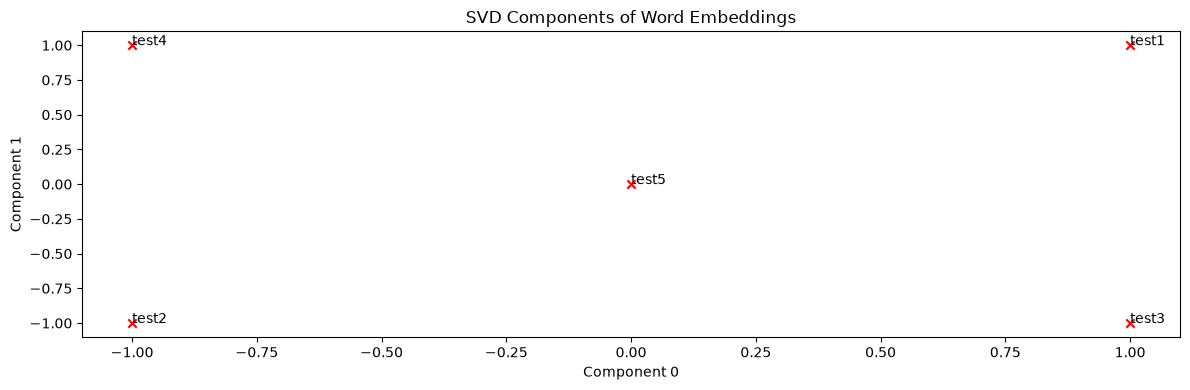

In [55]:
# ---------------------
# Run this sanity check
# Note that this is not an exhaustive check for correctness.
# The plot produced should look like the included file question_1.4_test.png 
# ---------------------

print ("-" * 80)
print ("Outputted Plot:")

M_reduced_plot_test = np.array([[1, 1], [-1, -1], [1, -1], [-1, 1], [0, 0]])
word2ind_plot_test = {'test1': 0, 'test2': 1, 'test3': 2, 'test4': 3, 'test5': 4}
words = ['test1', 'test2', 'test3', 'test4', 'test5']
plot_embeddings(M_reduced_plot_test, word2ind_plot_test, words)

print ("-" * 80)

### 问题 1.5：共现词向量图分析［书面题］（3 分）

现在，我们将把你编写的各个部分组合起来！首先，在大型电影评论语料库上，使用固定大小为 4 的窗口（默认窗口大小）计算共现矩阵。然后，使用 TruncatedSVD 计算每个词的二维嵌入。

TruncatedSVD 返回的是 U * S，因此我们需要对返回的向量进行归一化，使所有向量都分布在单位圆周围（因此，这里的接近程度指的是方向上的接近程度）。

**注意：**下面用于归一化的那行代码使用了 NumPy 中的*广播（broadcasting）*概念。如果你不了解广播，可以参考 Jake VanderPlas 的[《数组计算：广播》](https://jakevdp.github.io/PythonDataScienceHandbook/02.05-computation-on-arrays-broadcasting.html)。

运行下面的单元格以生成图表。运行过程可能需要几分钟。

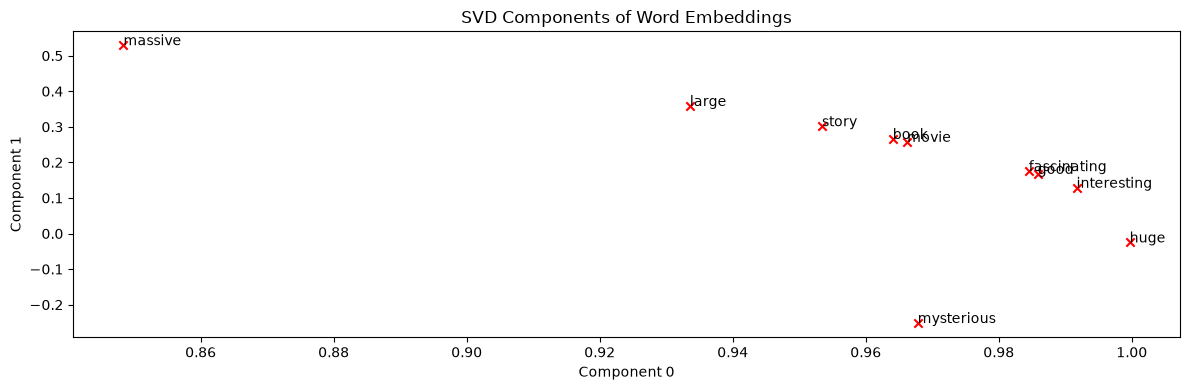

In [56]:
# -----------------------------
# 运行此单元格以生成图表
# -----------------------------
imdb_corpus = read_corpus()
M_co_occurrence, word2ind_co_occurrence = compute_co_occurrence_matrix(imdb_corpus)
M_reduced_co_occurrence = reduce_to_k_dim(M_co_occurrence, k=2)

# 对每一行进行缩放（归一化），使每个行向量的长度为 1
M_lengths = np.linalg.norm(M_reduced_co_occurrence, axis=1)
M_normalized = M_reduced_co_occurrence / M_lengths[:, np.newaxis]  # 使用广播机制

words = ['movie', 'book', 'mysterious', 'story', 'fascinating', 'good', 'interesting', 'large', 'massive', 'huge']

plot_embeddings(M_normalized, word2ind_co_occurrence, words)

**请确认你生成的图与作业压缩包中的 `question_1.5.png` 一致。如果不一致，请使用 `question_1.5.png` 中的图回答接下来的两个问题。**

a. 找出至少两组在二维嵌入空间中聚集在一起的词，并对你观察到的每个词簇给出解释。

#### <font color="red">在此填写你的答案。</font>

<div class="alert alert-block alert-success">
    <ol>
        <li><code>["book", "movie"]</code>：书籍和电影都具有结构化的叙事，包括开头、中间和结尾。此外，它们（例如小说和故事片）都会随着情节推进塑造人物，并通过对话展现人物的性格特点。</li>
        <li><code>["fascinating", "good", "interesting"]</code>：这三个形容词都表达了对某事物的积极反应，给出肯定性的评价。</li>
    </ol>
</div>

#### <font color="red">在此填写你的答案。</font>

<div class="alert alert-block alert-success">
    <ol>
        <li><code>["massive", "large", "huge"]</code>：这三个形容词都用于描述大小或规模，但它们在嵌入空间中彼此相距较远。</li>
        <li><code>["book", "movie", "story"]</code>：书籍和电影都围绕讲述故事展开，但 <code>"story"</code> 的词嵌入似乎与另外两个词的词嵌入有一定距离。</li>
        <li><code>["mysterious", "interesting"]</code>：这两个词都常用于描述能够激发好奇心的事物。</li>
    </ol>
</div>

## 第二部分：基于预测的词向量（15 分）

正如课堂上讨论的，近年来，基于预测的词向量展现出了更好的性能，例如 word2vec 和 GloVe（后者也利用了计数方法的优势）。在这里，我们将探索 GloVe 生成的词嵌入。有关 word2vec 和 GloVe 算法的更多细节，请回顾课程笔记和讲义。如果你想进一步挑战自己，可以尝试阅读 [GloVe 的原始论文](https://nlp.stanford.edu/pubs/glove.pdf)。

接下来，运行下面的单元格，将 GloVe 词向量加载到内存中。

**注意：** 如果这是你第一次运行这些单元格，即需要下载词嵌入模型，运行过程将需要几分钟。如果你之前已经运行过，再次运行时会直接加载模型，无需重新下载，大约需要 1～2 分钟。

In [80]:
def load_embedding_model():
    """ 加载 GloVe 词向量
        Return:
            wv_from_bin: 全部 400000 个词嵌入，每个嵌入的维度为 200
    """
    import gensim.downloader as api
    wv_from_bin = api.load("glove-wiki-gigaword-200")
    print("已加载的词表大小：%i" % len(list(wv_from_bin.index_to_key)))
    return wv_from_bin[:200]

wv_from_bin = load_embedding_model()

已加载的词表大小：400000


TypeError: 'slice' object is not iterable

#### 注意：如果遇到 “reset by peer”（连接被对端重置）错误，请重新运行该单元格以重新开始下载。

### 对词嵌入进行降维

让我们直接比较 GloVe 词嵌入与基于共现矩阵的词嵌入。为避免内存不足，我们将从 GloVe 词向量中抽取 40000 个作为样本进行处理。

运行下面的单元格以完成以下操作：

1. 将 40000 个 GloVe 词向量放入矩阵 M。
2. 运行 `reduce_to_k_dim`（你实现的截断 SVD 函数），将词向量从 200 维降至 2 维。

In [77]:
def get_matrix_of_vectors(wv_from_bin, required_words):
    """ 将 GloVe 词向量放入矩阵 M。
        Param:
            wv_from_bin: KeyedVectors 对象；从文件中加载的 400000 个 GloVe 词向量
        Return:
            M: 形状为 (词数, 200) 的 NumPy 矩阵，包含这些词向量
            word2idx: 将每个词映射到其在 M 中对应行号的字典
    """
    import random
    words = list(wv_from_bin.index_to_key)
    random.seed(225)
    random.shuffle(words)
    word2idx = {}
    M = []
    cur_idx = 0

    # 逐个获取 GloVe 向量并存入列表 M，并记录每个词对应的行号
    for word in words:
        try:
            # 单词 word 的 vector 添加到 M 中
            M.append(wv_from_bin.get_vector(word))
            word2idx[word] = cur_idx
            cur_idx += 1
        except KeyError:
            continue
    # 补充遗漏的词
    for w in required_words:
        if w in words:
            continue
        try:
            M.append(wv_from_bin.get_vector(w))
            word2ind[w] = cur_idx
            cur_idx += 1
        except KeyError:
            continue
    # 把列表堆叠成二维数组
    M = np.stack(M)
    return M, word2idx
    

In [78]:
# -----------------------------------------------------------------
# Run Cell to Reduce 200-Dimensional Word Embeddings to k Dimensions
# Note: This should be quick to run
# -----------------------------------------------------------------
M, word2ind = get_matrix_of_vectors(wv_from_bin, words)
M_reduced = reduce_to_k_dim(M, k=2)

# Rescale (normalize) the rows to make them each of unit-length
M_lengths = np.linalg.norm(M_reduced, axis=1)
M_reduced_normalized = M_reduced / M_lengths[:, np.newaxis] # broadcasting

**注意：如果你在本地电脑上遇到内存不足的问题，请尝试关闭其他应用程序，以释放更多内存。你也可以尝试重启电脑来释放额外的内存，然后立即运行 Jupyter Notebook，检查能否正常加载词向量。如果采取上述措施后，仍然无法在本地电脑上加载词嵌入，请在答疑时间寻求帮助，或联系课程工作人员。**

### 问题 2.1：GloVe 词向量图分析［书面题］（3 分）

运行下面的单元格，绘制以下词的二维 GloVe 词嵌入：

`['movie', 'book', 'mysterious', 'story', 'fascinating', 'good', 'interesting', 'large', 'massive', 'huge']`

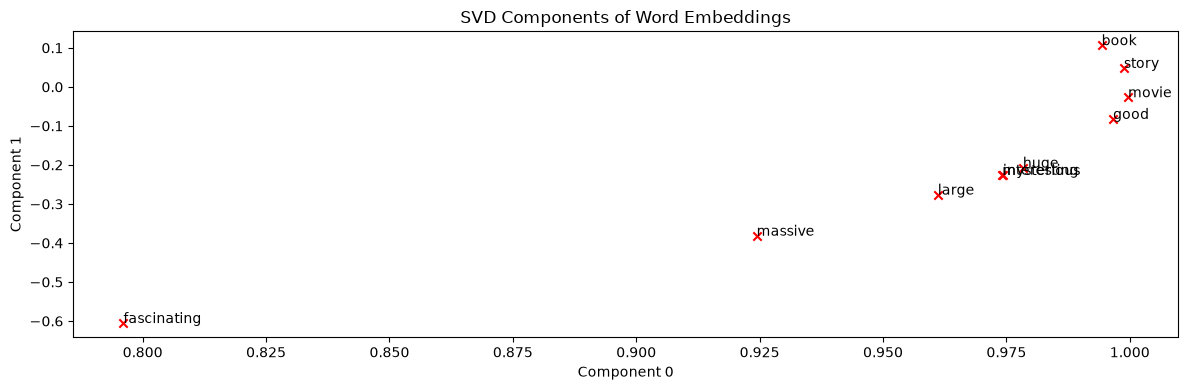

In [79]:
words = ['movie', 'book', 'mysterious', 'story', 'fascinating', 'good', 'interesting', 'large', 'massive', 'huge']

plot_embeddings(M_reduced_normalized, word2ind, words)

**请确认你生成的图与作业压缩包中的 `question_2.1.png` 一致。如果不一致，请使用 `question_2.1.png` 中的图（如有需要，也使用 `question_1.5.png` 中的图）回答接下来的两个问题。**

a. 与之前基于共现矩阵生成的图相比，这张图有哪些不同之处？请指出一点不同之处和一点相似之处。

#### <font color="red">在此填写你的答案。</font>

<div class="alert alert-block alert-success">
    与基于共现矩阵生成的词嵌入相比，<code>["book", "story", "movie"]</code> 仍然彼此接近。此外，<code>["massive", "large", "huge"]</code> 虽然仍然分散，但现在彼此之间的距离更近了。<br>
    另一方面，最明显的区别是，<code>["good", "interesting", "fascinating"]</code> 现在彼此相距更远。此外，<code>["mysterious", "interesting"]</code> 聚集在了一起。
</div>

b. 为什么 GloVe 词向量图（`question_2.1.png`）可能与之前基于共现矩阵生成的图（`question_1.5.png`）有所不同？

#### <font color="red">在此填写你的答案。</font>

<div class="alert alert-block alert-success">
    基于共现矩阵构建的词嵌入完全依赖于词语的共现次数，通常会产生高维、稀疏的向量，因此需要额外的降维方法（例如 SVD）。相比之下，GloVe 基于<strong>共现概率的比值</strong>学习低维嵌入空间，能够有效捕捉词语之间局部和全局的语义关系，从而生成更紧凑、语义信息更丰富的向量。
</div>

### 余弦相似度

现在我们已经有了词向量，接下来需要一种方法，根据这些向量量化词与词之间的相似程度。其中一种指标就是余弦相似度（cosine similarity）。我们将用它来寻找彼此“接近”或“远离”的词。

我们可以将 n 维向量看作 n 维空间中的点。从这个角度来看，[L1 距离](http://mathworld.wolfram.com/L1-Norm.html)和 [L2 距离](http://mathworld.wolfram.com/L2-Norm.html)可以帮助我们量化从一个点到另一个点“需要走多远”。另一种方法是考察两个向量之间的夹角。根据三角学，我们知道：

<img src="./imgs/inner_product.png" width="20%" style="float: center;"></img>

我们不必计算实际的夹角，而是直接使用 $similarity = \cos(\Theta)$ 来表示相似度。形式上，两个向量 $p$ 和 $q$ 之间的[余弦相似度](https://en.wikipedia.org/wiki/Cosine_similarity) $s$ 定义为：

$$
s = \frac{p \cdot q}{\|p\| \|q\|}, \quad \text{其中 } s \in [-1, 1]
$$

### 问题 2.2：具有多个含义的词（1.5 分）［编程题 + 书面题］

多义词（polysemes）和同形同音异义词（homonyms）都是具有多个含义的词（关于两者的区别，可以参考这个[维基百科页面](https://en.wikipedia.org/wiki/Polysemy)）。

找出一个*至少具有两种不同含义*的词，使其按余弦相似度排名前 10 的最相似词中，包含与*这两种含义都相关*的词。例如，"leaves" 的前 10 个最相似词同时体现了“离开”和“植物的叶片”两种含义；"scoop" 的结果则同时体现了“手持华夫饼甜筒”和“内幕消息”两种含义。你可能需要尝试多个多义词或同形同音异义词，才能找到一个符合要求的例子。

请写出你找到的词，以及前 10 个最相似词中体现出的多种含义。你认为，为什么你尝试的许多多义词或同形同音异义词不符合要求（即前 10 个最相似词只体现了该词的**一种**含义）？

**注意：** 你应该使用 `wv_from_bin.most_similar(word)` 函数获取前 10 个最相似词。该函数根据词表中其他所有词与给定词的余弦相似度，对它们进行排序。如需更多帮助，请参考 [Gensim 文档](https://radimrehurek.com/gensim/models/keyedvectors.html#gensim.models.keyedvectors.FastTextKeyedVectors.most_similar)。

In [81]:
# ------------------
# Write your implementation here.
wv_from_bin.most_similar("mouse")
# ------------------

[('mice', 0.6580957770347595),
 ('keyboard', 0.5548278093338013),
 ('rat', 0.5433949828147888),
 ('rabbit', 0.5192376971244812),
 ('cat', 0.5077415108680725),
 ('cursor', 0.5058691501617432),
 ('trackball', 0.5048903226852417),
 ('joystick', 0.49841049313545227),
 ('mickey', 0.47242844104766846),
 ('clicks', 0.4722805619239807)]

In [82]:
print(">>> Failed Example 1<<<")
display(wv_from_bin.most_similar("bank"))

print("\n>>> Failed Example 2 <<<")
display(wv_from_bin.most_similar("current"))

>>> Failed Example 1<<<


[('banks', 0.7625691294670105),
 ('banking', 0.6818838119506836),
 ('central', 0.6283639073371887),
 ('financial', 0.6166563034057617),
 ('credit', 0.6049751043319702),
 ('lending', 0.5980608463287354),
 ('monetary', 0.5963003039360046),
 ('bankers', 0.5913101434707642),
 ('loans', 0.5802940130233765),
 ('investment', 0.574020266532898)]


>>> Failed Example 2 <<<


[('present', 0.6921151876449585),
 ('future', 0.6827352046966553),
 ('its', 0.6762337684631348),
 ('the', 0.6630324721336365),
 ('change', 0.6562345027923584),
 ('term', 0.6546396017074585),
 ('same', 0.6516711711883545),
 ('this', 0.6397123336791992),
 ('of', 0.6339256763458252),
 ('year', 0.6308804750442505)]

#### <font color="red">在此填写你的答案。</font>

<div class="alert alert-block alert-success">
    当我们讨论动物等话题时，"mouse" 指一种小型啮齿动物，即“老鼠”。另一方面，它也指用于控制计算机屏幕上光标的实用设备，即“鼠标”。因此，我们可以观察到 "keyboard"（键盘）、"cursor"（光标）和 "clicks"（点击）等相似词。<br>
    许多多义词或同形同音异义词未能满足要求的一个原因是，其中一种含义往往在大多数上下文中占据<strong>主导地位</strong>。例如，"bank" 的前 10 个最相似词都与<strong>金融</strong>有关，没有词涉及河流两岸的陆地，即“河岸”。类似地，"current" 主要与<strong>时间</strong>概念相关。
</div>

### 问题 2.3：同义词与反义词（2 分）［编程题 + 书面题］

在考虑余弦相似度时，使用余弦距离来思考通常更方便。余弦距离就是 1 减去余弦相似度。

找出三个词 $(w_1, w_2, w_3)$，其中 $w_1$ 和 $w_2$ 是同义词，$w_1$ 和 $w_3$ 是反义词，但满足：

$$
\text{余弦距离}(w_1, w_3) < \text{余弦距离}(w_1, w_2)
$$

例如，$w_1$ = "happy"（快乐的）与 $w_3$ = "sad"（悲伤的）的距离，比它与 $w_2$ = "cheerful"（愉快的）的距离更近。请找出一个满足上述条件的不同例子。找到后，请解释这种看似违反直觉的结果可能是如何产生的。

你应该使用 `wv_from_bin.distance(w1, w2)` 函数计算两个词之间的余弦距离。如需更多帮助，请参考 [Gensim 文档](https://radimrehurek.com/gensim/models/keyedvectors.html#gensim.models.keyedvectors.FastTextKeyedVectors.distance)。

In [84]:
# ------------------
# 在此编写你的实现。
w1, w2, w3 = "interesting", "alluring", "boring"
dist1 = wv_from_bin.distance(w1, w2)
dist2 = wv_from_bin.distance(w1, w3)
print(f'同义词 "{w1}" 和 "{w2}" 的余弦距离为 {dist1:.2f}。')
print(f'反义词 "{w1}" 和 "{w3}" 的余弦距离为 {dist2:.2f}。')
# ------------------

同义词 "interesting" 和 "alluring" 的余弦距离为 0.61。
反义词 "interesting" 和 "boring" 的余弦距离为 0.53。


#### <font color="red">在此填写你的答案。</font>

<div class="alert alert-block alert-success">
    "interesting"（有趣的）和 "alluring"（诱人的、迷人的）都带有积极含义，常用于描述能够吸引注意力的事物。然而，从余弦相似度来看，"interesting" 与 "boring"（无聊的）反而更接近。这可能是因为 "interesting" 和 "boring" 适用于更广泛的语境，而 "alluring" 则更具体地与外表或审美上的吸引力相关。此外，"interesting" 和 "boring" 经常被用来作对比，例如“你看过的最有趣和最无聊的电影”。相比之下，"interesting" 和 "alluring" 很少在同一语境中一起使用。
</div>

### 问题 2.4：使用词向量进行类比［书面题］（1.5 分）

研究表明，词向量*有时*具备解决类比问题的能力。

例如，对于类比关系 "man : grandfather :: woman : x"（读作：“男人之于祖父，如同女人之于 x”），x 是什么？

在下面的单元格中，我们将展示如何使用 [Gensim 文档](https://radimrehurek.com/gensim/models/keyedvectors.html#gensim.models.keyedvectors.KeyedVectors.most_similar)中的 `most_similar` 函数，通过词向量找到 x。

该函数会寻找与 `positive` 列表中的词最相似、同时与 `negative` 列表中的词最不相似的词（并排除输入词，因为它们往往是最相似的；参见[这篇论文](https://www.aclweb.org/anthology/N18-2039.pdf)）。类比问题的答案将具有最高的余弦相似度（即返回结果中最大的数值）。

In [86]:
# 运行此单元格，求解类比关系：男人 : 祖父 :: 女人 : x
# x = grandfather - man + woman
pprint.pprint(wv_from_bin.most_similar(positive=['woman', 'grandfather'], negative=['man']))

[('grandmother', 0.7608445286750793),
 ('granddaughter', 0.7200808525085449),
 ('daughter', 0.7168302536010742),
 ('mother', 0.7151536345481873),
 ('niece', 0.7005683183670044),
 ('father', 0.6659887433052063),
 ('aunt', 0.6623408794403076),
 ('grandson', 0.6618767380714417),
 ('grandparents', 0.644661009311676),
 ('wife', 0.644535481929779)]


设 $m$、$g$、$w$ 和 $x$ 分别表示 `man`（男人）、`grandfather`（祖父）、`woman`（女人）以及答案对应的词向量。你的答案中**只能**使用向量 $m$、$g$、$w$ 和向量加减运算符 $+$、$-$：我们要使 $x$ 与哪个向量表达式的余弦相似度最大？

提示：词向量就是表示词的多维向量。你可以在二维坐标平面上任意选取各个向量的位置，画一个例子来辅助理解。相对于 `grandfather` 和答案的位置，`man` 和 `woman` 应当位于什么位置？

#### <font color="red">在此填写你的答案。</font>

$x = w + (g - m)$
<div class="alert alert-block alert-success">
    直观上，我们可以构造一个表达式，保留 "man"（男人）与 "grandfather"（祖父）之间的语义关系，并将这一关系应用到新的基础词 "woman"（女人）上。
</div>

### 问题 2.5：寻找类比关系［编程题 + 书面题］（1.5 分）

a. 对于前面的例子，显然 "grandmother"（祖母）能够补全这个类比。但为什么 `most_similar` 函数还会返回 "granddaughter"（孙女／外孙女）、"daughter"（女儿）或 "mother"（母亲）这样的词？请给出直观的解释。

#### <font color="red">在此填写你的答案。</font>

<div class="alert alert-block alert-success">
    可以看出，这些词都涉及<strong>血缘关系</strong>，直观上，这使它们在词向量空间中更加接近。
</div>

b. 找出一个在这些词向量中成立的类比例子（即预期的答案词排名第一）。请在答案中以 `x:y :: a:b` 的形式写出完整的类比关系。如果你认为该类比比较复杂，请用一两句话解释为什么它成立。

**注意：** 你可能需要尝试多个类比，才能找到一个成立的例子！

In [90]:
# For example: x, y, a, b = ("", "", "", "")
# ------------------
# Write your implementation here.
x, y, a, b = ("paris", "france", "tokyo", "japan")
# ------------------

# Test the solution
assert wv_from_bin.most_similar(positive=[a, y], negative=[x])[0][0] == b

#### <font color="red">在此填写你的答案。</font>

<div class="alert alert-block alert-success">
    "paris : france :: tokyo : japan"：“巴黎”之于“法国”，如同“东京”之于“日本”。
</div>

### 问题 2.6：错误的类比［编程题 + 书面题］（1.5 分）

a. 在下面的例子中，我们期望得到类比关系 "hand : glove :: foot : **sock**"（手 : 手套 :: 脚 : **袜子**），但实际却得到了意料之外的结果。请解释这一类比出现这种结果的一个可能原因。

In [91]:
pprint.pprint(wv_from_bin.most_similar(positive=['foot', 'glove'], negative=['hand']))

[('45,000-square', 0.4922032058238983),
 ('15,000-square', 0.4649604558944702),
 ('10,000-square', 0.45447564125061035),
 ('6,000-square', 0.44975772500038147),
 ('3,500-square', 0.4441334009170532),
 ('700-square', 0.44257503747940063),
 ('50,000-square', 0.4356396794319153),
 ('3,000-square', 0.43486514687538147),
 ('30,000-square', 0.4330596923828125),
 ('footed', 0.43236875534057617)]


#### <font color="red">在此填写你的答案。</font>

<div class="alert alert-block alert-success">
    查看前 10 个最相似词后，我们发现许多结果似乎不合常理，例如类比 "hand : glove :: foot : 45,000-square"。我们推测，这可能是由于数据质量较差，或训练样本数量不足，导致模型无法正确识别预期的类比关系。
</div>

b. 再找一个在这些词向量中*不成立*的类比例子。在答案中，以 `x:y :: a:b` 的形式写出预期的类比关系，并指出词向量实际给出的 **b 的错误值**（在前面的例子中，该错误值为 **`'45,000-square'`**）。

In [92]:
# For example: x, y, a, b = ("", "", "", "")
# ------------------
# Write your implementation here.
x, y, a, b = ("empire", "emperor", "country", "president")
# ------------------
pprint.pprint(wv_from_bin.most_similar(positive=[a, y], negative=[x]))
assert wv_from_bin.most_similar(positive=[a, y], negative=[x])[0][0] != b

[('saying', 0.5144181251525879),
 ('should', 0.4947633743286133),
 ('here', 0.49109557271003723),
 ('him', 0.4902016520500183),
 ('government', 0.48641976714134216),
 ('urged', 0.47555848956108093),
 ('so', 0.46992477774620056),
 ('countries', 0.4688504934310913),
 ('year', 0.46670961380004883),
 ('because', 0.46662184596061707)]


#### <font color="red">在此填写你的答案。</font>

<div class="alert alert-block alert-success">
    预期的类比关系是 "empire : emperor :: country : president"（帝国 : 皇帝 :: 国家 : 总统），但我们得到了 "saying"（说）和 "should"（应该）等完全不相关的错误结果。
</div>

### 问题 2.7：词向量偏见的引导分析［书面题］（1 分）

我们需要意识到词嵌入中隐含的偏见，例如性别、种族、性取向等方面的偏见。偏见可能带来危害，因为使用这些模型的应用程序可能会强化刻板印象。

运行下面的单元格，考察：

(a) 哪些词与 "man"（男性）和 "profession"（职业）最相似，同时与 "woman"（女性）最不相似；

(b) 哪些词与 "woman"（女性）和 "profession"（职业）最相似，同时与 "man"（男性）最不相似。

请指出女性关联词列表与男性关联词列表之间的差异，并解释这些差异如何反映了性别偏见。

In [94]:
# 运行此单元格
# 这里，positive 指定希望结果与之相似的词列表，
# negative 指定希望结果与之最不相似的词列表。

pprint.pprint(wv_from_bin.most_similar(positive=['man', 'profession'], negative=['woman']))
print()
pprint.pprint(wv_from_bin.most_similar(positive=['woman', 'profession'], negative=['man']))

[('reputation', 0.5250176787376404),
 ('professions', 0.5178037881851196),
 ('skill', 0.49046966433525085),
 ('skills', 0.49005505442619324),
 ('ethic', 0.4897659420967102),
 ('business', 0.487585186958313),
 ('respected', 0.4859202802181244),
 ('practice', 0.482104629278183),
 ('regarded', 0.4778572916984558),
 ('life', 0.4760662019252777)]

[('professions', 0.5957458019256592),
 ('practitioner', 0.4988412857055664),
 ('teaching', 0.48292139172554016),
 ('nursing', 0.48211804032325745),
 ('vocation', 0.4788965880870819),
 ('teacher', 0.47160348296165466),
 ('practicing', 0.46937811374664307),
 ('educator', 0.46524327993392944),
 ('physicians', 0.4628995656967163),
 ('professionals', 0.4601394236087799)]


#### <font color="red">在此填写你的答案。</font>

<div class="alert alert-block alert-success">
    与 "woman"（女性）和 "profession"（职业）最相似的词主要与照护类工作相关，其中许多工作通常<strong>薪酬较低</strong>。相比之下，与 "man"（男性）相关的职业更容易关联到 "reputation"（声誉）和 "respected"（受尊重的）等总体上带有积极含义的词。这种差异表明，我们的词嵌入模型中存在性别刻板印象，可能对下游任务产生负面影响。
</div>

In [95]:
# ------------------
# 在此编写你的实现。
obj1, obj2 = "boy", "girl"
subject = "toy"

print(">>> 玩具 - 男孩 <<<")
pprint.pprint(wv_from_bin.most_similar(positive=[obj1, subject], negative=[obj2]))
print()
print(">>> 玩具 - 女孩 <<<")
pprint.pprint(wv_from_bin.most_similar(positive=[obj2, subject], negative=[obj1]))
# ------------------

>>> 玩具 - 男孩 <<<
[('toys', 0.7157087922096252),
 ('hasbro', 0.5164632797241211),
 ('robot', 0.47317108511924744),
 ('pet', 0.4670490026473999),
 ('manufacturer', 0.4668163061141968),
 ('mattel', 0.4582391679286957),
 ('lego', 0.45811760425567627),
 ('miniature', 0.4441472887992859),
 ('makers', 0.44298243522644043),
 ('manufactured', 0.44275349378585815)]

>>> 玩具 - 女孩 <<<
[('toys', 0.7094953060150146),
 ('doll', 0.5932914614677429),
 ('dolls', 0.570662260055542),
 ('barbie', 0.5407706499099731),
 ('mattel', 0.5328551530838013),
 ('accessories', 0.52069091796875),
 ('hasbro', 0.49227219820022583),
 ('jewelry', 0.47385695576667786),
 ('lego', 0.4690813422203064),
 ('apparel', 0.46136239171028137)]


#### <font color="red">在此填写你的答案。</font>

<div class="alert alert-block alert-success">
    我们再次使用性别刻板印象来说明，偏见存在于不同年龄群体中。例如，男孩往往与 "robot"（机器人）和 "lego"（乐高）等玩具相关联，而女孩则通常与 "doll"（玩偶）和 "barbie"（芭比娃娃）相关联。这清楚地表明了刻板印象的存在。
</div>

### 问题 2.9：思考偏见［书面题］（2 分）

a. 解释偏见进入词向量的一种途径，并简要描述一个能够体现这种偏见来源的现实案例。你的现实案例应聚焦于词向量，而不是其他 AI 系统（例如 ChatGPT）中的偏见。

#### <font color="red">在此填写你的答案。</font>

<div class="alert alert-block alert-success">
    词嵌入中最直观的偏见来源是用于训练模型的语料库。如果训练样本（例如文档）包含针对特定种族的偏见，模型就可能学习并反映这些偏见，从而导致<strong>种族歧视</strong>。<br>
    一个现实案例是 Reddit 等平台上存在的<strong>网络种族主义</strong>。根据 <a href="https://aclanthology.org/N19-1062.pdf">Manzini 等人的研究</a>，词嵌入可能表现出种族偏见，例如将 "black"（黑人／黑色的）与 "criminal"（罪犯）关联起来，该研究的表 1 展示了这一现象。
</div>

b. 有什么方法可以减轻词向量表现出的偏见？请提出一种方法，并简要描述一个展示该方法的现实案例。

#### <font color="red">在此填写你的答案。</font>

<div class="alert alert-block alert-success">
    常用的偏见缓解方法包括<strong>硬去偏（hard debiasing）</strong>和<strong>软去偏（soft debiasing）</strong>（<a href="https://arxiv.org/pdf/1607.06520">Bolukbasi 等人</a>）。第一步是识别能够表征偏见的向量子空间，然后从原始词嵌入中移除位于该子空间中的特定关联（例如性别关联）。<br>
    <a href="https://aclanthology.org/N19-1062.pdf">Manzini 等人</a>将这项研究推广到多类别情形，通过识别其中的偏见子空间，应用推广后的多类别去偏方法，缓解多个维度（例如性别、种族和宗教）上的偏见。
</div>

# <font color="blue">提交说明</font>

1. 点击 Jupyter Notebook 顶部的保存按钮。
2. 选择 **Cell → All Output → Clear**，清除所有单元格的输出（但保留所有单元格的内容）。
3. 选择 **Cell → Run All**，按顺序运行所有单元格。这将需要几分钟。
4. 全部重新运行完成后，选择 **File → Download as → PDF via LaTeX**。如果使用 “PDF via LaTeX” 时遇到问题，也可以将网页另存为 PDF。<font color="blue">请确保所有答案，尤其是编程部分，都完整显示在 PDF 中。</font>由于代码单元格中的长行不会自动换行，课程提供的代码被截断是可以接受的。
5. 检查 PDF 文件，确保所有答案都已包含在内，并且显示正确。**评分人员只能看到这份 PDF！**
6. 在 Gradescope 上提交你的 PDF。